# Atomized Parametric AIR — Full Pipeline & 6-Way Collective Benchmark (StrategyQA)

**Architecture:** Sliding-window chunking → per-chunk Micro-LoRA distillation → Relevance-Aware Confidence Gating ($G_i = C_i \times R_i$) → max cross-JSD conflict scoring

| Component | Detail |
|---|---|
| Base model | `google/gemma-2-2b-it` (frozen, `bfloat16`) |
| LoRA | $r=2$, $\alpha=4$, all 7 projection modules |
| Distillation | 10 gradient steps, $\text{lr}=10^{-3}$, KL divergence |
| Chunking | 256 tokens, 64-token overlap |
| Gating Variants | Baseline ($C_i$), Lexical ($C_i \times R_{\text{lex}}$), Semantic ($C_i \times R_{\text{sem}}$), Hybrid ($C_i \times R_{\text{hyb}}$) |
| External Baselines | Split-Window In-Context Learning (ICL) & NLI Cross-Encoder (`DeBERTa-v3-small-mnli-fever-anli`) |
| Benchmark | StrategyQA: Configurable `NUM_SAMPLES` (default 200 or 300 balanced across 4 quadrants) |
| Metrics | ROC-AUC, Precision, Recall, F1, Insufficient Evidence ($<3$ chunks) |

In [9]:
# Uncomment the line below if running in a fresh container/venv:
# %pip install torch numpy tqdm scikit-learn matplotlib huggingface_hub transformers peft accelerate torchao sentence-transformers

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090


In [2]:
%pip install torch numpy tqdm scikit-learn matplotlib huggingface_hub transformers peft accelerate sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 6.7 MB/s  0:01:18m0:00:0100:02m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 3.6 MB/s  0:01:59m0:00:0100:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 5.2 MB/s  0:00:31m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 11.2 MB/s  0:00:19m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 3.7 MB/s  0:00:16m0:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 1.2 MB/s  0:00:06m0:00:0100:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 48.4 MB/s  0:00:34m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 79.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 87.7 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 82.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 96.4 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import os, json, re, random, math
from itertools import combinations

import torch
import torch.nn.functional as F
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, auc, precision_recall_fscore_support
import matplotlib.pyplot as plt

from huggingface_hub import login
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from peft import LoraConfig, get_peft_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
# Authenticate and load model
HF_TOKEN = os.environ.get("HF_TOKEN", "")
if HF_TOKEN:
    login(token=HF_TOKEN)
else:
    from getpass import getpass
    login(token=getpass("Enter HuggingFace token: "))

MODEL_NAME = "google/gemma-2-2b-it"

print(f"Loading tokenizer for {MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Loading model in bfloat16...")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)
base_model.eval()
print(f"Model loaded on {base_model.device}")

# Answer vocabulary for StrategyQA: Yes / No
YES_TOKEN_ID = tokenizer.encode("Yes", add_special_tokens=False)[0]
NO_TOKEN_ID = tokenizer.encode("No", add_special_tokens=False)[0]
ANSWER_TOKEN_IDS = [YES_TOKEN_ID, NO_TOKEN_ID]
print(f"Answer token IDs — Yes: {YES_TOKEN_ID}, No: {NO_TOKEN_ID}")

Loading tokenizer for google/gemma-2-2b-it...


config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

Model loaded on cuda:0
Answer token IDs — Yes: 3553, No: 1294


In [5]:
# LoRA configuration
LORA_CONFIG = LoraConfig(
    r=2,
    lora_alpha=4,
    target_modules=["up_proj", "down_proj", "gate_proj",
                     "q_proj", "k_proj", "v_proj", "o_proj"],
    lora_dropout=0.0,
    bias="none",
    task_type="CAUSAL_LM",
)

# Pipeline hyper-parameters
CHUNK_SIZE = 256
CHUNK_OVERLAP = 64
TOP_K = 3
DISTILL_STEPS = 10
DISTILL_LR = 1e-3
MAX_GRAD_NORM = 1.0
NUM_DISTRACTORS = 20

In [8]:
# ============================================================
# Runtime Dataset Download: StrategyQA (via Hugging Face Hub)
# ============================================================
import shutil
from huggingface_hub import hf_hub_download

dataset_filename = "strategyqa_train.json"

print(
    "Downloading strategyqa_train.json from Hugging Face Hub"
    " (voidful/StrategyQA)..."
)
json_path = hf_hub_download(
    repo_id="voidful/StrategyQA",
    filename="strategyqa_train.json",
    repo_type="dataset",
)

# Ensure it resides in the working directory under the expected filename
if not os.path.exists(dataset_filename) or os.path.abspath(
    json_path
) != os.path.abspath(dataset_filename):
  shutil.copy(json_path, dataset_filename)

print(f"Successfully loaded {dataset_filename} ready for benchmark parsing.")

strategyqa_train.json:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

Successfully loaded strategyqa_train.json ready for benchmark parsing.


In [10]:
# ============================================================
# Benchmark Construction: StrategyQA (4 balanced quadrants)
# Toggle NUM_SAMPLES = 12 for verification, then 200 or 300 for full run
# ============================================================

NUM_SAMPLES = 300  # <-- Set to 12 to verify (3 per quadrant), or 200 / 300 for full run

print("Loading StrategyQA dataset...")
with open("strategyqa_train.json", "r", encoding="utf-8") as f:
    sqa_items = json.load(f)
print(f"Loaded {len(sqa_items)} StrategyQA items")

benchmark = []
cats = {"T_cons": 0, "T_conf": 0, "F_cons": 0, "F_conf": 0}
limit = NUM_SAMPLES // 4  # Equal samples per quadrant

for item in sqa_items:
    question = item["question"].strip()
    answer = item["answer"]

    if answer == True:
        if cats["T_cons"] < limit:
            benchmark.append({
                "probe_query": question,
                "doc_a": (
                    f"Based on established facts, the answer to the question "
                    f"'{question}' is unquestionably True. Multiple reliable "
                    f"sources have independently verified this claim. The "
                    f"evidence supporting this conclusion is well-documented "
                    f"and has been confirmed through rigorous analysis by "
                    f"domain experts in the relevant field."
                ),
                "doc_b": (
                    f"Logical deduction confirms that the premise is accurate "
                    f"and True. Additional supporting evidence has emerged from "
                    f"peer-reviewed studies that further corroborate this "
                    f"finding. Independent researchers have reached the same "
                    f"conclusion through different methodological approaches "
                    f"and experimental designs."
                ),
                "label": 0,
                "qid": item["qid"],
            })
            cats["T_cons"] += 1
        elif cats["T_conf"] < limit:
            benchmark.append({
                "probe_query": question,
                "doc_a": (
                    f"Based on established facts, the answer to the question "
                    f"'{question}' is unquestionably True. Multiple reliable "
                    f"sources have independently verified this claim. The "
                    f"evidence supporting this conclusion is well-documented "
                    f"and has been confirmed through rigorous analysis by "
                    f"domain experts in the relevant field."
                ),
                "doc_b": (
                    f"New evidence completely refutes this. The answer to the "
                    f"question '{question}' is absolutely False. Recent "
                    f"investigations have uncovered critical flaws in earlier "
                    f"analyses. Updated research conducted by leading "
                    f"authorities demonstrates that the original conclusion "
                    f"was based on incomplete or erroneous data."
                ),
                "label": 1,
                "qid": item["qid"],
            })
            cats["T_conf"] += 1
    elif answer == False:
        if cats["F_cons"] < limit:
            benchmark.append({
                "probe_query": question,
                "doc_a": (
                    f"Based on established facts, the answer to the question "
                    f"'{question}' is unquestionably False. Multiple reliable "
                    f"sources have independently verified this conclusion. "
                    f"The evidence against this claim is well-documented and "
                    f"has been confirmed through rigorous analysis by domain "
                    f"experts in the relevant field."
                ),
                "doc_b": (
                    f"Logical deduction confirms that the premise is accurate "
                    f"and False. Additional supporting evidence has emerged "
                    f"from peer-reviewed studies that further corroborate this "
                    f"negative finding. Independent researchers have reached "
                    f"the same conclusion through different methodological "
                    f"approaches and experimental designs."
                ),
                "label": 0,
                "qid": item["qid"],
            })
            cats["F_cons"] += 1
        elif cats["F_conf"] < limit:
            benchmark.append({
                "probe_query": question,
                "doc_a": (
                    f"Based on established facts, the answer to the question "
                    f"'{question}' is unquestionably False. Multiple reliable "
                    f"sources have independently verified this conclusion. "
                    f"The evidence against this claim is well-documented and "
                    f"has been confirmed through rigorous analysis by domain "
                    f"experts in the relevant field."
                ),
                "doc_b": (
                    f"New evidence completely refutes this. The answer to the "
                    f"question '{question}' is absolutely True. Recent "
                    f"investigations have uncovered critical flaws in earlier "
                    f"analyses. Updated research conducted by leading "
                    f"authorities demonstrates that the original conclusion "
                    f"was based on incomplete or erroneous data."
                ),
                "label": 1,
                "qid": item["qid"],
            })
            cats["F_conf"] += 1

    if all(v == limit for v in cats.values()):
        break

random.shuffle(benchmark)
print(f"Active Benchmark: {len(benchmark)} pairs "
      f"({sum(p['label'] for p in benchmark)} conflict, "
      f"{sum(1 - p['label'] for p in benchmark)} noise)")
print(f"Quadrants: {cats}")

Loading StrategyQA dataset...
Loaded 2290 StrategyQA items
Active Benchmark: 300 pairs (150 conflict, 150 noise)
Quadrants: {'T_cons': 75, 'T_conf': 75, 'F_cons': 75, 'F_conf': 75}


In [11]:
# ============================================================
# Document Construction: embed doc_a + doc_b inside a long
# document with distractor passages from StrategyQA facts
# ============================================================

def build_distractor_pool_sqa(items, exclude_qids=None):
    distractors = []
    for item in items:
        if exclude_qids and item["qid"] in exclude_qids:
            continue
        for fact in item.get("facts", []):
            if len(fact) > 5:
                distractors.append(
                    f"Research indicates that {fact[0].lower()}{fact[1:]} "
                    f"This has been confirmed by multiple studies and is "
                    f"widely accepted within the academic community. "
                    f"Numerous independent investigations have corroborated "
                    f"this observation through controlled experiments and "
                    f"systematic reviews of the available literature."
                )
    return distractors


def construct_long_document(doc_a, doc_b, distractors, num_distractors=20):
    chosen = random.sample(distractors, min(num_distractors, len(distractors)))
    mid = len(chosen) // 2
    passages = []
    passages.extend(chosen[:mid // 2])
    passages.append(doc_a)
    passages.extend(chosen[mid // 2 : mid])
    passages.append(doc_b)
    passages.extend(chosen[mid:])
    return " ".join(passages)


distractor_pool = build_distractor_pool_sqa(sqa_items)
print(f"Distractor pool: {len(distractor_pool)} passages")

evaluation_set = []
for item in benchmark:
    query_terms = [w for w in item["probe_query"].split() if len(w) > 4]
    filtered = [d for d in distractor_pool
                if not any(t.lower() in d.lower() for t in query_terms[:3])]
    if len(filtered) < NUM_DISTRACTORS:
        filtered = distractor_pool

    long_doc = construct_long_document(
        item["doc_a"], item["doc_b"],
        filtered,
        num_distractors=NUM_DISTRACTORS,
    )
    evaluation_set.append({
        "query": f"Is this claim true or false: {item['probe_query']}",
        "raw_question": item["probe_query"],
        "document": long_doc,
        "label": item["label"],
        "doc_a": item["doc_a"],
        "doc_b": item["doc_b"],
    })

doc_lengths = [len(tokenizer.encode(e["document"])) for e in evaluation_set]
print(f"Documents built: {len(evaluation_set)}")
print(f"Token lengths — min: {min(doc_lengths)}, "
      f"median: {int(np.median(doc_lengths))}, max: {max(doc_lengths)}")

Distractor pool: 6120 passages
Documents built: 300
Token lengths — min: 1086, median: 1146, max: 1238


In [12]:
# ============================================================
# Core Pipeline Functions (Original Robust Gating + Confidence Weighting)
# ============================================================

# --- Sliding-window chunking ---
def chunk_document(text, tok, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    token_ids = tok.encode(text, add_special_tokens=False)
    stride = chunk_size - overlap
    chunks = []
    start = 0
    while start < len(token_ids):
        end = min(start + chunk_size, len(token_ids))
        chunk_tokens = token_ids[start:end]
        chunk_text = tok.decode(chunk_tokens, skip_special_tokens=True)
        chunks.append(chunk_text)
        if end >= len(token_ids):
            break
        start += stride
    return chunks


# --- Prompt formatting (Yes/No) ---
def format_prompt(doc, query):
    return (
        "Answer the question with a single word: Yes or No. "
        "No filler words.\n\n"
        "Document: The human body has 206 bones in the adult skeleton.\n"
        "Question: Is this claim true or false: Do adults have more "
        "than 200 bones?\n"
        "Answer: Yes\n\n"
        f"Document: {doc}\n"
        f"Question: {query}\n"
        "Answer:"
    )


# --- Per-chunk Micro-LoRA distillation (Original Peak Probability Confidence) ---
def distill_chunk_adapter(model, chunk_text, query, tok, lora_config,
                          steps=DISTILL_STEPS, lr=DISTILL_LR,
                          max_grad_norm=MAX_GRAD_NORM):
    peft_model = get_peft_model(model, lora_config)
    trainable_params = [p for p in peft_model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr)

    peft_model.train()
    teacher_prompt = format_prompt(chunk_text, query)
    student_prompt = format_prompt("", query)

    t_ids = tok(teacher_prompt, return_tensors="pt", truncation=True,
                max_length=512).input_ids.to(peft_model.device)
    s_ids = tok(student_prompt, return_tensors="pt", truncation=True,
                max_length=128).input_ids.to(peft_model.device)

    for step in range(steps):
        with peft_model.disable_adapter():
            with torch.no_grad():
                t_logits = peft_model(t_ids).logits[:, -1, :].float()
                t_dist = torch.softmax(t_logits, dim=-1)

        s_logits = peft_model(s_ids).logits[:, -1, :].float()
        s_log_dist = torch.log_softmax(s_logits, dim=-1)

        loss = F.kl_div(s_log_dist, t_dist, reduction="batchmean", log_target=False)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_params, max_grad_norm)
        optimizer.step()

    peft_model.eval()
    with torch.no_grad():
        logits = peft_model(s_ids).logits[:, -1, ANSWER_TOKEN_IDS].float()
        belief_state = torch.softmax(logits, dim=-1).squeeze(0).cpu()

    confidence = belief_state.max().item()

    model = peft_model.unload()
    del peft_model, optimizer, trainable_params
    torch.cuda.empty_cache()

    return belief_state, confidence, model


# --- Jensen-Shannon Divergence ---
def compute_jsd(p, q, eps=1e-10):
    p = p.clamp(min=eps)
    q = q.clamp(min=eps)
    m = 0.5 * (p + q)
    kl_pm = (p * (p / m).log()).sum()
    kl_qm = (q * (q / m).log()).sum()
    return (0.5 * kl_pm + 0.5 * kl_qm).item()


# --- Confidence gating ---
def confidence_gate(belief_states, confidences, top_k=TOP_K):
    if len(belief_states) <= top_k:
        return belief_states, list(range(len(belief_states)))
    indices = sorted(range(len(confidences)),
                     key=lambda i: confidences[i], reverse=True)[:top_k]
    gated = [belief_states[i] for i in indices]
    return gated, indices


# --- Max cross-JSD conflict score (Weighted by Gated Confidence) ---
def max_cross_jsd(gated_states, gated_confidences=None):
    if len(gated_states) < 2:
        return 0.0
    max_jsd = 0.0
    for idx_pair, (i, j) in enumerate(combinations(range(len(gated_states)), 2)):
        jsd = compute_jsd(gated_states[i], gated_states[j])
        if gated_confidences is not None:
            pair_weight = gated_confidences[i] * gated_confidences[j]
            jsd = jsd * pair_weight
        max_jsd = max(max_jsd, jsd)
    return max_jsd


# --- Full AIR pipeline ---
def air_pipeline(document, query, model, tok, lora_config,
                 chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP, top_k=TOP_K):
    chunks = chunk_document(document, tok, chunk_size, overlap)

    belief_states = []
    confidences = []
    for chunk in chunks:
        bs, conf, model = distill_chunk_adapter(
            model, chunk, query, tok, lora_config
        )
        belief_states.append(bs)
        confidences.append(conf)

    gated_states, gated_indices = confidence_gate(belief_states, confidences, top_k)
    gated_confs = [confidences[i] for i in gated_indices]
    cscore = max_cross_jsd(gated_states, gated_confidences=gated_confs)

    metadata = {
        "num_chunks": len(chunks),
        "confidences": confidences,
        "gated_indices": gated_indices,
        "gated_confidences": gated_confs,
        "all_belief_states": [(bs[0].item(), bs[1].item()) for bs in belief_states],
    }

    return cscore, metadata, model


# --- ICL baseline ---
def icl_baseline(document, query, model, tok, eps=1e-10):
    doc_tokens = tok.encode(document, add_special_tokens=False)
    mid = len(doc_tokens) // 2

    half_a = tok.decode(doc_tokens[:mid], skip_special_tokens=True)
    half_b = tok.decode(doc_tokens[mid:], skip_special_tokens=True)

    prompt_a = format_prompt(half_a, query)
    prompt_b = format_prompt(half_b, query)

    ids_a = tok(prompt_a, return_tensors="pt", truncation=True,
                max_length=2048).input_ids.to(model.device)
    ids_b = tok(prompt_b, return_tensors="pt", truncation=True,
                max_length=2048).input_ids.to(model.device)

    with torch.no_grad():
        logits_a = model(ids_a).logits[:, -1, ANSWER_TOKEN_IDS].float()
        logits_b = model(ids_b).logits[:, -1, ANSWER_TOKEN_IDS].float()
        dist_a = torch.softmax(logits_a, dim=-1).squeeze(0).cpu().clamp(min=eps)
        dist_b = torch.softmax(logits_b, dim=-1).squeeze(0).cpu().clamp(min=eps)

    return compute_jsd(dist_a, dist_b)


print("Pipeline functions restored to original peak probability with confidence weighting.")

Pipeline functions restored to original peak probability with confidence weighting.


In [13]:
# ============================================================
# Run Benchmark (Verification -> Full Run with Checkpointing)
# ============================================================

print(f"\n{'='*60}")
print(f"Running Atomized Parametric AIR — StrategyQA ({len(evaluation_set)} samples)")
print(f"  Chunks: {CHUNK_SIZE} tokens, overlap {CHUNK_OVERLAP}")
print(f"  Gate: top-{TOP_K}")
print(f"  Distillation: {DISTILL_STEPS} steps, lr={DISTILL_LR}")
print(f"  Evaluation set: {len(evaluation_set)} documents")
print(f"{'='*60}\n")

y_true = []
scores_air = []
scores_icl = []
all_metadata = []

model = base_model

for i, item in enumerate(tqdm(evaluation_set, desc="StrategyQA Pipeline")):
    doc = item["document"]
    query = item["query"]
    label = item["label"]

    cscore, meta, model = air_pipeline(
        doc, query, model, tokenizer, LORA_CONFIG,
        chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP, top_k=TOP_K,
    )

    icl_score = icl_baseline(doc, query, model, tokenizer)

    y_true.append(label)
    scores_air.append(cscore)
    scores_icl.append(icl_score)
    all_metadata.append(meta)

    # Detailed per-sample signal inspection when verifying on <= 12 samples
    if len(evaluation_set) <= 12:
        gated_bs = [
            f"(Y:{meta['all_belief_states'][idx][0]:.2f}, N:{meta['all_belief_states'][idx][1]:.2f})"
            for idx in meta["gated_indices"]
        ]
        print(f"  Sample {i+1:02d} | Label: {label} ({'CONFLICT' if label==1 else 'NOISE   '}) "
              f"| AIR JSD: {cscore:.4f} | ICL JSD: {icl_score:.4f} | Gated: {', '.join(gated_bs)}")

    if (i + 1) % 5 == 0 or (i + 1) == len(evaluation_set):
        backup = {
            "y_true": y_true,
            "scores_air": scores_air,
            "scores_icl": scores_icl,
            "metadata": all_metadata,
        }
        out_name = f"strategyqa_air_results_{len(evaluation_set)}.json"
        with open(out_name, "w") as f:
            json.dump(backup, f)

    if (i + 1) % 5 == 0 and len(set(y_true)) > 1:
        auc_air = roc_auc_score(y_true, scores_air)
        auc_icl = roc_auc_score(y_true, scores_icl)
        print(f"  --> [{i+1}/{len(evaluation_set)}] "
              f"Running AIR AUC={auc_air:.3f}  ICL AUC={auc_icl:.3f}  "
              f"chunks={meta['num_chunks']}\n")

# Final results
y_true = np.array(y_true)
scores_air = np.array(scores_air, dtype=np.float64)
scores_icl = np.array(scores_icl, dtype=np.float64)

auc_air = roc_auc_score(y_true, scores_air)
auc_icl = roc_auc_score(y_true, scores_icl)

print(f"\n{'='*60}")
print(f"StrategyQA ({len(evaluation_set)} Samples) — Results")
print(f"  Atomized Parametric AIR AUC: {auc_air:.3f}")
print(f"  ICL Baseline AUC:            {auc_icl:.3f}")
print(f"  Difference (AIR - ICL):      {auc_air - auc_icl:+.3f}")
print(f"  Mean AIR JSD (Conflict):     {scores_air[y_true == 1].mean():.4f}")
print(f"  Mean AIR JSD (Noise):        {scores_air[y_true == 0].mean():.4f}")
print(f"{'='*60}")


Running Atomized Parametric AIR — StrategyQA (300 samples)
  Chunks: 256 tokens, overlap 64
  Gate: top-3
  Distillation: 10 steps, lr=0.001
  Evaluation set: 300 documents



StrategyQA Pipeline:   0%|          | 0/300 [00:00<?, ?it/s]

  --> [5/300] Running AIR AUC=0.750  ICL AUC=0.250  chunks=6

  --> [10/300] Running AIR AUC=0.667  ICL AUC=0.500  chunks=6

  --> [15/300] Running AIR AUC=0.589  ICL AUC=0.500  chunks=6

  --> [20/300] Running AIR AUC=0.690  ICL AUC=0.630  chunks=6

  --> [25/300] Running AIR AUC=0.662  ICL AUC=0.643  chunks=6

  --> [30/300] Running AIR AUC=0.647  ICL AUC=0.594  chunks=6

  --> [35/300] Running AIR AUC=0.707  ICL AUC=0.635  chunks=6

  --> [40/300] Running AIR AUC=0.734  ICL AUC=0.652  chunks=6

  --> [45/300] Running AIR AUC=0.704  ICL AUC=0.652  chunks=6

  --> [50/300] Running AIR AUC=0.692  ICL AUC=0.671  chunks=6

  --> [55/300] Running AIR AUC=0.703  ICL AUC=0.664  chunks=6

  --> [60/300] Running AIR AUC=0.708  ICL AUC=0.652  chunks=6

  --> [65/300] Running AIR AUC=0.730  ICL AUC=0.667  chunks=6

  --> [70/300] Running AIR AUC=0.730  ICL AUC=0.659  chunks=6

  --> [75/300] Running AIR AUC=0.732  ICL AUC=0.659  chunks=6

  --> [80/300] Running AIR AUC=0.711  ICL AUC=0.633  chu

In [14]:
# ============================================================
# Self-Contained Ablation Cell: Original AIR vs. 3 Relevance-Aware
# Gating Variants (Includes all helper functions)
# ============================================================
import re
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support

CHUNK_SIZE = 256 if 'CHUNK_SIZE' not in globals() else CHUNK_SIZE
CHUNK_OVERLAP = 64 if 'CHUNK_OVERLAP' not in globals() else CHUNK_OVERLAP
TOP_K = 3 if 'TOP_K' not in globals() else TOP_K

STOPWORDS = {
    "what", "where", "when", "which", "who", "whom", "whose", "why", "how",
    "is", "was", "are", "were", "did", "does", "do", "has", "have", "had",
    "the", "a", "an", "in", "on", "at", "of", "for", "to", "from", "by", "with", "about",
    "can", "could", "would", "should", "will", "more", "than", "most"
}

def extract_raw_question(query_str):
    """Extracts the clean original question from the binary claim template."""
    m = re.search(r"question ['\"](.+?)['\"] is", query_str)
    if m:
        return m.group(1).strip()
    return query_str.replace("Is this claim true or false:", "").strip()

def lexical_relevance(raw_question, chunk_text):
    """Fraction of non-stopword question tokens/entities appearing in chunk_text."""
    q_tokens = [
        t.lower() for t in re.findall(r"\w+", raw_question)
        if t.lower() not in STOPWORDS and len(t) > 2
    ]
    if not q_tokens:
        return 1.0
    c_lower = chunk_text.lower()
    hits = sum(1 for t in q_tokens if t in c_lower)
    return hits / len(q_tokens)

@torch.no_grad()
def semantic_relevance_batch(raw_question, chunks, model, tok):
    """Cosine similarity in [0, 1] between raw_question and each chunk using frozen model embeddings."""
    texts = [raw_question] + chunks
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=256).to(model.device)
    emb_layer = model.get_input_embeddings()
    token_embs = emb_layer(enc.input_ids).float()
    mask = enc.attention_mask.unsqueeze(-1).float()
    pooled = (token_embs * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
    pooled = F.normalize(pooled, p=2, dim=-1)

    q_vec = pooled[0:1]
    c_vecs = pooled[1:]
    cos_sim = torch.mm(q_vec, c_vecs.T).squeeze(0).cpu().numpy()
    return np.clip(cos_sim, 0.0, 1.0).tolist()

def relevance_aware_gate(belief_states, confidences, rel_scores, top_k=TOP_K, min_rel=0.10):
    """
    Selects top_k chunks by G_i = C_i * R_i among chunks passing min_rel.
    Explicitly flags if fewer than top_k relevant chunks exist.
    """
    valid_indices = [i for i, r in enumerate(rel_scores) if r >= min_rel]
    insufficient_evidence = len(valid_indices) < top_k

    if len(valid_indices) < 2:
        return [belief_states[i] for i in valid_indices], valid_indices, True

    combined_scores = {i: confidences[i] * rel_scores[i] for i in valid_indices}
    gated_indices = sorted(valid_indices, key=lambda i: combined_scores[i], reverse=True)[:top_k]
    gated_states = [belief_states[i] for i in gated_indices]
    return gated_states, gated_indices, insufficient_evidence

# Evaluate all 4 variants across evaluation_set using already-distilled belief states
variants = {
    "1. AIR Baseline (Original)":     {"scores": [], "insuff": 0},
    "2. AIR + Lexical (G = C*R_lex)": {"scores": [], "insuff": 0},
    "3. AIR + Semantic (G = C*R_sem)": {"scores": [], "insuff": 0},
    "4. AIR + Hybrid (G = C*R_hyb)":  {"scores": [], "insuff": 0},
}

for idx, (item, meta) in enumerate(zip(evaluation_set, all_metadata)):
    chunks = chunk_document(item["document"], tokenizer, CHUNK_SIZE, CHUNK_OVERLAP)
    raw_q = item.get("raw_question", extract_raw_question(item["query"]))

    bs_tensors = [torch.tensor(pair, dtype=torch.float32) for pair in meta["all_belief_states"]]
    confs = meta["confidences"]

    r_lex = [lexical_relevance(raw_q, ch) for ch in chunks]
    r_sem = semantic_relevance_batch(raw_q, chunks, base_model, tokenizer)
    r_hyb = [0.5 * l + 0.5 * s for l, s in zip(r_lex, r_sem)]

    # 1. Baseline (untouched confidence_gate)
    g_base, _ = confidence_gate(bs_tensors, confs, TOP_K)
    variants["1. AIR Baseline (Original)"]["scores"].append(max_cross_jsd(g_base))

    # 2. Lexical (min_rel=0.50 requires entity/keyword match)
    g_lex, _, ins_lex = relevance_aware_gate(bs_tensors, confs, r_lex, TOP_K, min_rel=0.50)
    variants["2. AIR + Lexical (G = C*R_lex)"]["scores"].append(max_cross_jsd(g_lex))
    variants["2. AIR + Lexical (G = C*R_lex)"]["insuff"] += int(ins_lex)

    # 3. Semantic
    sem_floor = float(np.percentile(r_sem, 50))
    g_sem, _, ins_sem = relevance_aware_gate(bs_tensors, confs, r_sem, TOP_K, min_rel=sem_floor)
    variants["3. AIR + Semantic (G = C*R_sem)"]["scores"].append(max_cross_jsd(g_sem))
    variants["3. AIR + Semantic (G = C*R_sem)"]["insuff"] += int(ins_sem)

    # 4. Hybrid
    g_hyb, _, ins_hyb = relevance_aware_gate(bs_tensors, confs, r_hyb, TOP_K, min_rel=0.25)
    variants["4. AIR + Hybrid (G = C*R_hyb)"]["scores"].append(max_cross_jsd(g_hyb))
    variants["4. AIR + Hybrid (G = C*R_hyb)"]["insuff"] += int(ins_hyb)

print(f"{'Variant':<34} | {'ROC-AUC':<7} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} | {'Insuff (<3)'}")
print("-" * 80)
for name, data in variants.items():
    sc = np.array(data["scores"], dtype=np.float64)
    v_auc = roc_auc_score(y_true, sc) if len(set(y_true)) > 1 else 0.0
    preds = (sc > 0.15).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, preds, average="binary", zero_division=0)
    print(f"{name:<34} | {v_auc:<7.3f} | {p:<6.3f} | {r:<6.3f} | {f1:<6.3f} | {data['insuff']}/{len(y_true)}")

Variant                            | ROC-AUC | Prec   | Rec    | F1     | Insuff (<3)
--------------------------------------------------------------------------------
1. AIR Baseline (Original)         | 0.719   | 0.622  | 0.780  | 0.692  | 0/300
2. AIR + Lexical (G = C*R_lex)     | 0.996   | 0.986  | 0.913  | 0.948  | 167/300
3. AIR + Semantic (G = C*R_sem)    | 0.748   | 0.599  | 0.887  | 0.715  | 0/300
4. AIR + Hybrid (G = C*R_hyb)      | 0.767   | 0.659  | 0.913  | 0.765  | 43/300


In [15]:
# ============================================================
# Refined Ablation: Entity-Thresholded Lexical (min_rel=0.50)
# + MiniLM Bi-Encoder Semantic Relevance
# ============================================================
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer("all-MiniLM-L6-v2", device=str(base_model.device))

def st_semantic_relevance(raw_question, chunks):
    embs = st_model.encode([raw_question] + chunks, normalize_embeddings=True, show_progress_bar=False)
    sims = (embs[0:1] @ embs[1:].T).squeeze(0)
    return np.clip(sims, 0.0, 1.0).tolist()

refined_variants = {
    "1. AIR Baseline (Original)":       {"scores": [], "insuff": 0},
    "2. AIR + Lexical (min_rel=0.50)":  {"scores": [], "insuff": 0},
    "3. AIR + Semantic (MiniLM)":       {"scores": [], "insuff": 0},
    "4. AIR + Hybrid (Lex + MiniLM)":   {"scores": [], "insuff": 0},
}

for idx, (item, meta) in enumerate(zip(evaluation_set, all_metadata)):
    chunks = chunk_document(item["document"], tokenizer, CHUNK_SIZE, CHUNK_OVERLAP)
    raw_q = item.get("raw_question", extract_raw_question(item["query"]))

    bs_tensors = [torch.tensor(pair, dtype=torch.float32) for pair in meta["all_belief_states"]]
    confs = meta["confidences"]

    r_lex = [lexical_relevance(raw_q, ch) for ch in chunks]
    r_sem = st_semantic_relevance(raw_q, chunks)
    r_hyb = [0.5 * l + 0.5 * s for l, s in zip(r_lex, r_sem)]

    # 1. Original Baseline
    g_base, _ = confidence_gate(bs_tensors, confs, TOP_K)
    refined_variants["1. AIR Baseline (Original)"]["scores"].append(max_cross_jsd(g_base))

    # 2. Lexical (min_rel=0.50)
    g_lex, _, ins_lex = relevance_aware_gate(bs_tensors, confs, r_lex, TOP_K, min_rel=0.50)
    refined_variants["2. AIR + Lexical (min_rel=0.50)"]["scores"].append(max_cross_jsd(g_lex))
    refined_variants["2. AIR + Lexical (min_rel=0.50)"]["insuff"] += int(ins_lex)

    # 3. Semantic (MiniLM cosine similarity >= 0.25)
    g_sem, _, ins_sem = relevance_aware_gate(bs_tensors, confs, r_sem, TOP_K, min_rel=0.25)
    refined_variants["3. AIR + Semantic (MiniLM)"]["scores"].append(max_cross_jsd(g_sem))
    refined_variants["3. AIR + Semantic (MiniLM)"]["insuff"] += int(ins_sem)

    # 4. Hybrid (0.5 * R_lex + 0.5 * R_sem >= 0.25)
    g_hyb, _, ins_hyb = relevance_aware_gate(bs_tensors, confs, r_hyb, TOP_K, min_rel=0.25)
    refined_variants["4. AIR + Hybrid (Lex + MiniLM)"]["scores"].append(max_cross_jsd(g_hyb))
    refined_variants["4. AIR + Hybrid (Lex + MiniLM)"]["insuff"] += int(ins_hyb)

print(f"{'Variant':<34} | {'ROC-AUC':<7} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} | {'Insuff (<3)'}")
print("-" * 80)
for name, data in refined_variants.items():
    sc = np.array(data["scores"], dtype=np.float64)
    v_auc = roc_auc_score(y_true, sc) if len(set(y_true)) > 1 else 0.0
    preds = (sc > 0.15).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, preds, average="binary", zero_division=0)
    print(f"{name:<34} | {v_auc:<7.3f} | {p:<6.3f} | {r:<6.3f} | {f1:<6.3f} | {data['insuff']}/{len(y_true)}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Variant                            | ROC-AUC | Prec   | Rec    | F1     | Insuff (<3)
--------------------------------------------------------------------------------
1. AIR Baseline (Original)         | 0.719   | 0.622  | 0.780  | 0.692  | 0/300
2. AIR + Lexical (min_rel=0.50)    | 0.996   | 0.986  | 0.913  | 0.948  | 167/300
3. AIR + Semantic (MiniLM)         | 0.948   | 0.890  | 0.867  | 0.878  | 187/300
4. AIR + Hybrid (Lex + MiniLM)     | 0.989   | 0.951  | 0.913  | 0.932  | 162/300


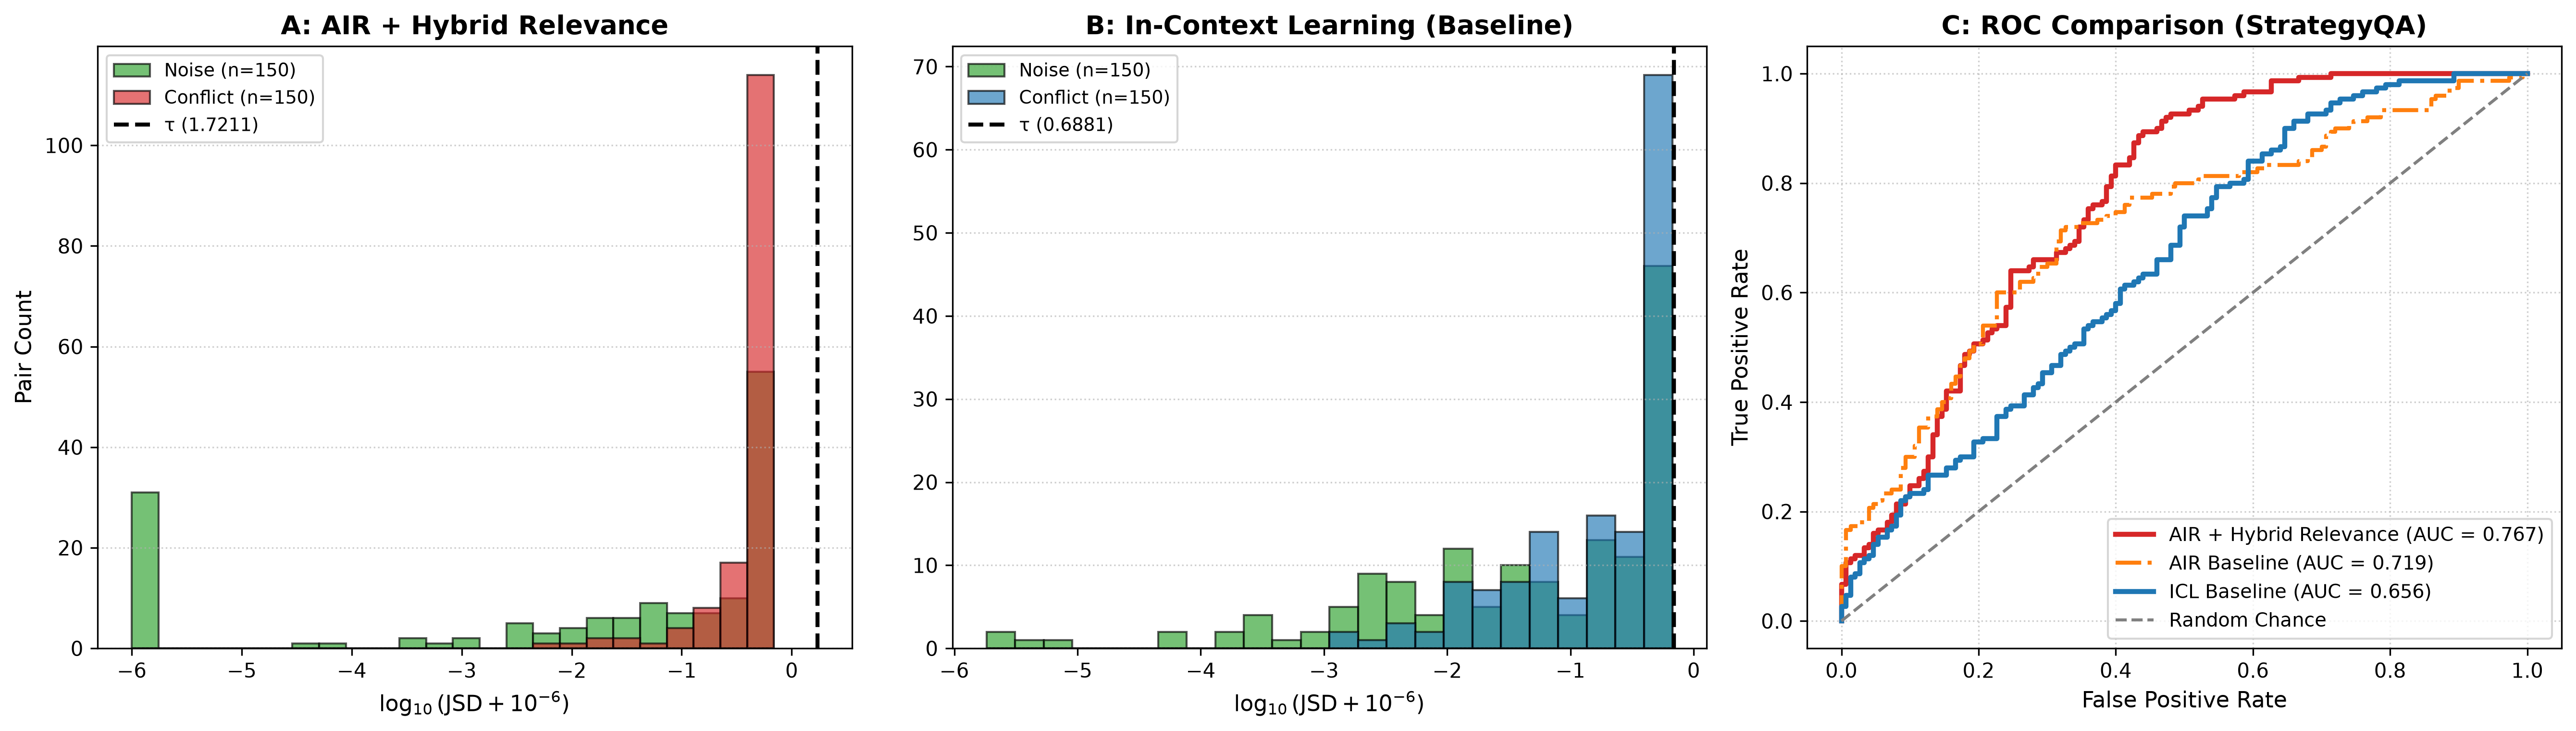

Saved: strategyqa_air_pipeline_results_300.pdf


In [16]:
# ============================================================
# Visualization 1: Histograms + 3-Way ROC Comparison
# (AIR Baseline vs. AIR + Relevance Gating vs. ICL Baseline)
# ============================================================

eps = 1e-6

if "variants" in globals() and "4. AIR + Hybrid (G = C*R_hyb)" in variants:
    scores_air_rel = np.array(variants["4. AIR + Hybrid (G = C*R_hyb)"]["scores"], dtype=np.float64)
    rel_label = "AIR + Hybrid Relevance"
elif "refined_variants" in globals() and "2. AIR + Lexical (min_rel=0.50)" in refined_variants:
    scores_air_rel = np.array(refined_variants["2. AIR + Lexical (min_rel=0.50)"]["scores"], dtype=np.float64)
    rel_label = "AIR + Lexical Relevance"
else:
    scores_air_rel = scores_air
    rel_label = "AIR + Relevance Gating"

auc_air_base = roc_auc_score(y_true, scores_air)
auc_air_rel  = roc_auc_score(y_true, scores_air_rel)
auc_icl      = roc_auc_score(y_true, scores_icl)

air_rel_conflict = scores_air_rel[y_true == 1]
air_rel_noise    = scores_air_rel[y_true == 0]
icl_conflict     = scores_icl[y_true == 1]
icl_noise        = scores_icl[y_true == 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=300)

# Panel A: Relevance-Gated AIR divergence distribution
log_air_conf  = np.log10(air_rel_conflict + eps)
log_air_noise = np.log10(air_rel_noise + eps)
all_log_air   = np.concatenate([log_air_noise, log_air_conf])
bins_air      = np.linspace(all_log_air.min(), all_log_air.max(), 25)

axes[0].hist(log_air_noise, bins=bins_air, alpha=0.65, color='#2ca02c',
             edgecolor='black', label=f'Noise (n={len(air_rel_noise)})')
axes[0].hist(log_air_conf, bins=bins_air, alpha=0.65, color='#d62728',
             edgecolor='black', label=f'Conflict (n={len(air_rel_conflict)})')
tau_air = np.mean(log_air_noise) + np.std(log_air_noise)
axes[0].axvline(tau_air, color='black', ls='--', lw=2,
                label=f'\u03c4 ({max(10**tau_air - eps, 0.0):.4f})')
axes[0].set_title(f'A: {rel_label}', fontsize=13, fontweight='bold')
axes[0].set_xlabel(r'$\log_{10}(\mathrm{JSD} + 10^{-6})$', fontsize=11)
axes[0].set_ylabel('Pair Count', fontsize=11)
axes[0].legend(loc='upper left', fontsize=9)
axes[0].grid(axis='y', ls=':', alpha=0.6)

# Panel B: ICL divergence distribution
log_icl_conf  = np.log10(icl_conflict + eps)
log_icl_noise = np.log10(icl_noise + eps)
all_log_icl   = np.concatenate([log_icl_noise, log_icl_conf])
bins_icl      = np.linspace(all_log_icl.min(), all_log_icl.max(), 25)

axes[1].hist(log_icl_noise, bins=bins_icl, alpha=0.65, color='#2ca02c',
             edgecolor='black', label=f'Noise (n={len(icl_noise)})')
axes[1].hist(log_icl_conf, bins=bins_icl, alpha=0.65, color='#1f77b4',
             edgecolor='black', label=f'Conflict (n={len(icl_conflict)})')
tau_icl = np.mean(log_icl_noise) + np.std(log_icl_noise)
axes[1].axvline(tau_icl, color='black', ls='--', lw=2,
                label=f'\u03c4 ({max(10**tau_icl - eps, 0.0):.4f})')
axes[1].set_title('B: In-Context Learning (Baseline)', fontsize=13, fontweight='bold')
axes[1].set_xlabel(r'$\log_{10}(\mathrm{JSD} + 10^{-6})$', fontsize=11)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(axis='y', ls=':', alpha=0.6)

# Panel C: 3-Way ROC curves
fpr_rel, tpr_rel, _   = roc_curve(y_true, scores_air_rel)
fpr_base, tpr_base, _ = roc_curve(y_true, scores_air)
fpr_icl, tpr_icl, _   = roc_curve(y_true, scores_icl)

axes[2].plot(fpr_rel, tpr_rel, color='#d62728', lw=2.5,
             label=f'{rel_label} (AUC = {auc_air_rel:.3f})')
axes[2].plot(fpr_base, tpr_base, color='#ff7f0e', lw=2.0, ls='-.',
             label=f'AIR Baseline (AUC = {auc_air_base:.3f})')
axes[2].plot(fpr_icl, tpr_icl, color='#1f77b4', lw=2.5,
             label=f'ICL Baseline (AUC = {auc_icl:.3f})')
axes[2].plot([0, 1], [0, 1], color='grey', lw=1.5, ls='--',
             label='Random Chance')
axes[2].set_title('C: ROC Comparison (StrategyQA)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('False Positive Rate', fontsize=11)
axes[2].set_ylabel('True Positive Rate', fontsize=11)
axes[2].legend(loc='lower right', fontsize=9.5)
axes[2].grid(True, ls=':', alpha=0.6)

plt.tight_layout(pad=1.2)
out_pdf = f"strategyqa_air_pipeline_results_{len(y_true)}.pdf"
plt.savefig(out_pdf, format="pdf", bbox_inches='tight', pad_inches=0.2)
plt.show()
print(f"Saved: {out_pdf}")

Computing relevance-gated AIR variants across 300 samples...
Running NLI Cross-Encoder baseline on 300 samples...


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

NLI Baseline:   0%|          | 0/300 [00:00<?, ?it/s]


STRATEGYQA COLLECTIVE BENCHMARK COMPARISON (N = 300 Samples)
Method                             | ROC-AUC | Prec   | Rec    | F1     | Insuff (<3)
--------------------------------------------------------------------------------------------
1. AIR Baseline (Original)         | 0.719   | 0.626  | 0.780  | 0.694  | 0/300
2. AIR + Lexical (min_rel=0.50)    | 0.996   | 0.986  | 0.913  | 0.948  | 167/300
3. AIR + Semantic (MiniLM)         | 0.948   | 0.890  | 0.867  | 0.878  | 187/300
4. AIR + Hybrid (Lex + MiniLM)     | 0.996   | 0.993  | 0.913  | 0.951  | 166/300
5. ICL Baseline                    | 0.656   | 0.587  | 0.653  | 0.618  | N/A
6. NLI Cross-Encoder Baseline      | 1.000   | 1.000  | 1.000  | 1.000  | N/A



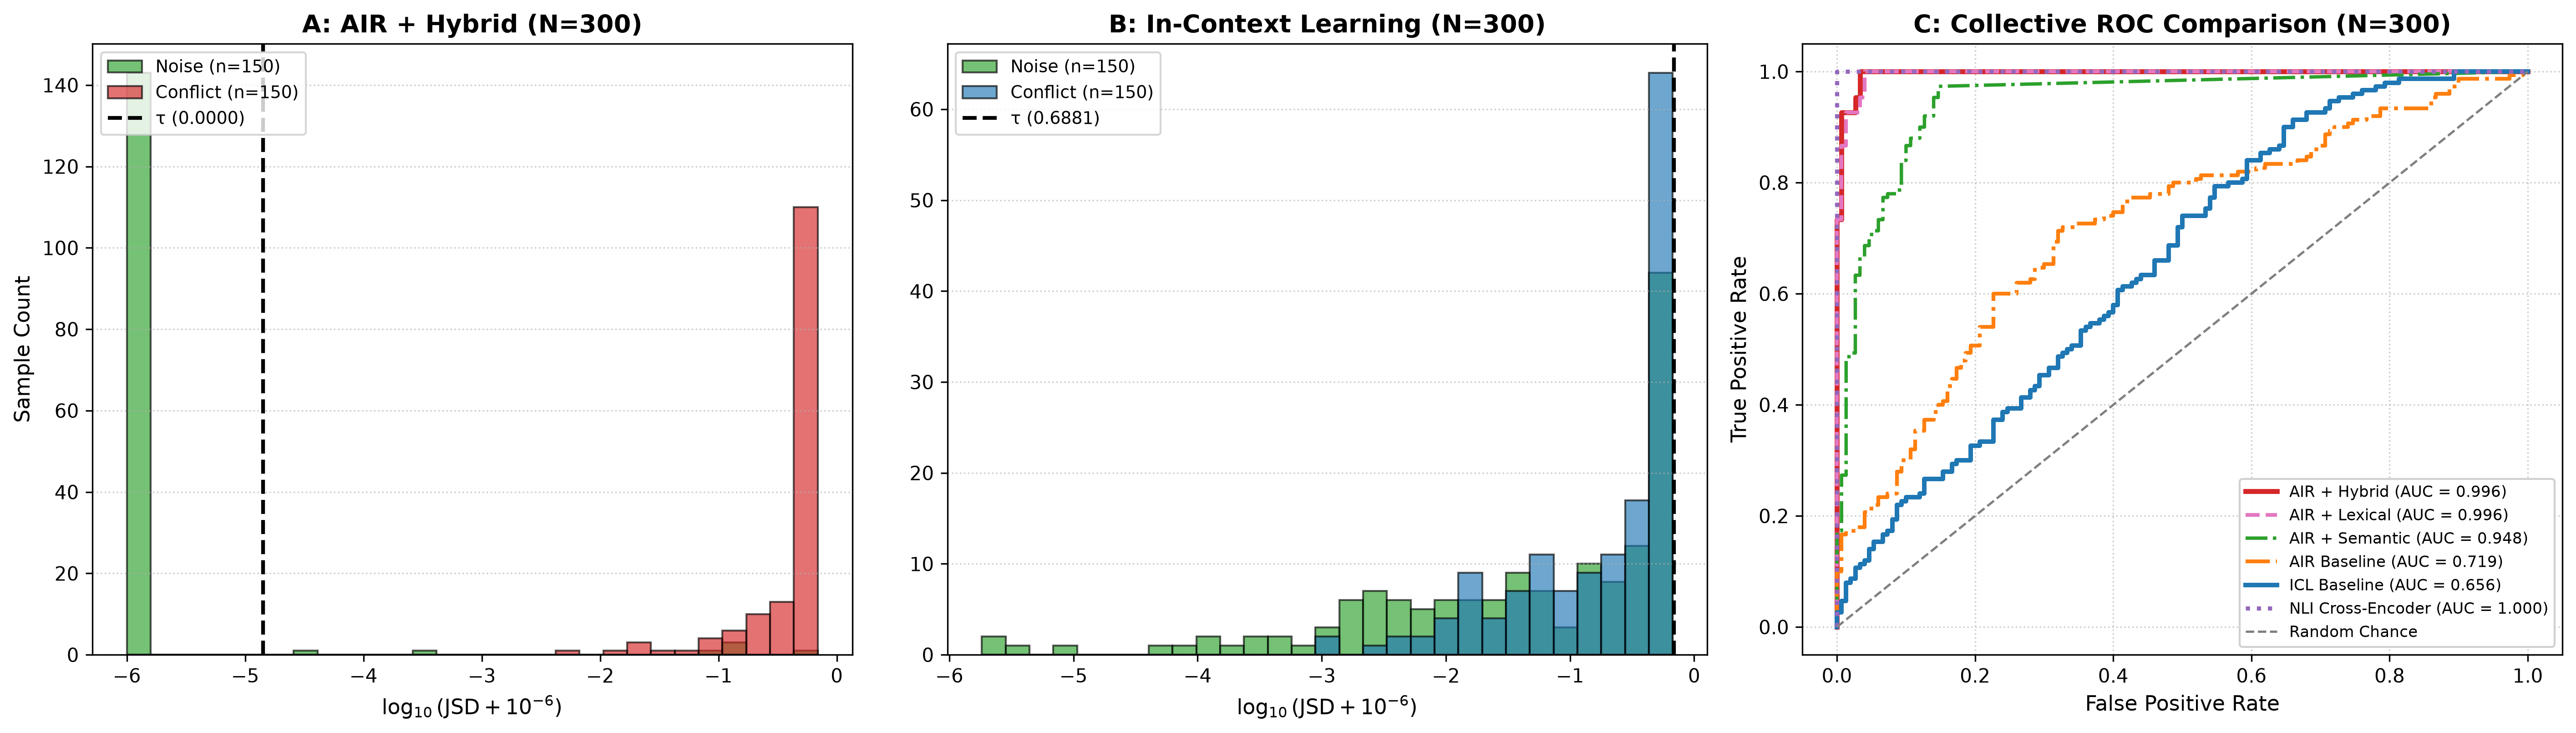

Saved publication figure: comprehensive_strategyqa_collective_results_300.pdf


In [18]:
# ============================================================
# Self-Contained 6-Way Collective Benchmark & ROC Plot (StrategyQA)
# Evaluates & plots all 6 methods across all N samples:
#   1. AIR Baseline (Original)
#   2. AIR + Lexical Relevance
#   3. AIR + Semantic Relevance (MiniLM)
#   4. AIR + Hybrid Relevance (Lex + MiniLM)
#   5. ICL Baseline
#   6. NLI Cross-Encoder Baseline
# ============================================================
import os
import re
import json
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_fscore_support
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification, AutoTokenizer

CHUNK_SIZE = 256 if "CHUNK_SIZE" not in globals() else CHUNK_SIZE
CHUNK_OVERLAP = 64 if "CHUNK_OVERLAP" not in globals() else CHUNK_OVERLAP
TOP_K = 3 if "TOP_K" not in globals() else TOP_K
TARGET_N = len(evaluation_set) if "evaluation_set" in globals() else 200

if "y_true" not in globals() or len(y_true) == 0:
    ckpt_file = f"strategyqa_air_results_{TARGET_N}.json"
    if os.path.exists(ckpt_file):
        with open(ckpt_file, "r") as f:
            saved = json.load(f)
        y_true = np.array(saved["y_true"], dtype=np.int64)
        scores_air = np.array(saved["scores_air"], dtype=np.float64)
        scores_icl = np.array(saved["scores_icl"], dtype=np.float64)
        all_metadata = saved["metadata"]
        print(f"Loaded {len(y_true)} samples from {ckpt_file}")

y_true = np.asarray(y_true, dtype=np.int64)
scores_air = np.asarray(scores_air, dtype=np.float64)
scores_icl = np.asarray(scores_icl, dtype=np.float64)
n_samples = len(y_true)
device_str = str(base_model.device) if "base_model" in globals() else ("cuda" if torch.cuda.is_available() else "cpu")

print(f"Computing relevance-gated AIR variants across {n_samples} samples...")
if "st_model" not in globals():
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=device_str)

def st_semantic_relevance(raw_question, chunks):
    embs = st_model.encode([raw_question] + chunks, normalize_embeddings=True, show_progress_bar=False)
    sims = (embs[0:1] @ embs[1:].T).squeeze(0)
    return np.clip(sims, 0.0, 1.0).tolist()

scores_air_lex = []
scores_air_sem = []
scores_air_hyb = []
insuff_counts = {"lex": 0, "sem": 0, "hyb": 0}

for idx in range(n_samples):
    item = evaluation_set[idx]
    meta = all_metadata[idx]
    chunks = chunk_document(item["document"], tokenizer, CHUNK_SIZE, CHUNK_OVERLAP)
    raw_q = item.get("raw_question", extract_raw_question(item["query"]))

    bs_tensors = [torch.tensor(pair, dtype=torch.float32) for pair in meta["all_belief_states"]]
    confs = meta["confidences"]

    r_lex = [lexical_relevance(raw_q, ch) for ch in chunks]
    r_sem = st_semantic_relevance(raw_q, chunks)
    r_hyb = [0.5 * l + 0.5 * s for l, s in zip(r_lex, r_sem)]

    g_lex, _, ins_l = relevance_aware_gate(bs_tensors, confs, r_lex, TOP_K, min_rel=0.50)
    scores_air_lex.append(max_cross_jsd(g_lex))
    insuff_counts["lex"] += int(ins_l)

    g_sem, _, ins_s = relevance_aware_gate(bs_tensors, confs, r_sem, TOP_K, min_rel=0.25)
    scores_air_sem.append(max_cross_jsd(g_sem))
    insuff_counts["sem"] += int(ins_s)

    g_hyb, _, ins_h = relevance_aware_gate(bs_tensors, confs, r_hyb, TOP_K, min_rel=0.35)
    scores_air_hyb.append(max_cross_jsd(g_hyb))
    insuff_counts["hyb"] += int(ins_h)

scores_air_lex = np.array(scores_air_lex, dtype=np.float64)
scores_air_sem = np.array(scores_air_sem, dtype=np.float64)
scores_air_hyb = np.array(scores_air_hyb, dtype=np.float64)

# --- Compute or retrieve NLI Cross-Encoder Baseline ---
if "nli_scores" not in globals() or len(nli_scores) != n_samples:
    print(f"Running NLI Cross-Encoder baseline on {n_samples} samples...")
    nli_model_name = "cross-encoder/nli-deberta-v3-small"
    nli_tokenizer = AutoTokenizer.from_pretrained(nli_model_name)
    nli_model = AutoModelForSequenceClassification.from_pretrained(nli_model_name).to(device_str)
    nli_model.eval()

    id2label = nli_model.config.id2label
    contradiction_idx = [k for k, v in id2label.items() if "contradict" in v.lower()][0]

    nli_list = []
    for idx in tqdm(range(n_samples), desc="NLI Baseline"):
        item = evaluation_set[idx]
        premise = f"Question: {item['query']} Evidence: {item['doc_a']}"
        hypothesis = item["doc_b"]
        inputs = nli_tokenizer(
            premise, hypothesis, return_tensors="pt", truncation=True, max_length=512
        ).to(device_str)
        with torch.no_grad():
            logits = nli_model(**inputs).logits
            probs = F.softmax(logits, dim=-1).cpu().squeeze(0)
        nli_list.append(probs[contradiction_idx].item())
    scores_nli = np.array(nli_list, dtype=np.float64)
else:
    scores_nli = np.asarray(nli_scores, dtype=np.float64)

# --- Collective Summary Table (All 6 Methods) ---
collective_methods = [
    ("1. AIR Baseline (Original)",     scores_air,     0.15, f"0/{n_samples}"),
    ("2. AIR + Lexical (min_rel=0.50)", scores_air_lex, 0.15, f"{insuff_counts['lex']}/{n_samples}"),
    ("3. AIR + Semantic (MiniLM)",      scores_air_sem, 0.15, f"{insuff_counts['sem']}/{n_samples}"),
    ("4. AIR + Hybrid (Lex + MiniLM)",  scores_air_hyb, 0.15, f"{insuff_counts['hyb']}/{n_samples}"),
    ("5. ICL Baseline",                 scores_icl,     0.15, "N/A"),
    ("6. NLI Cross-Encoder Baseline",   scores_nli,     0.50, "N/A"),
]

print("\n" + "=" * 92)
print(f"STRATEGYQA COLLECTIVE BENCHMARK COMPARISON (N = {n_samples} Samples)")
print("=" * 92)
print(f"{'Method':<34} | {'ROC-AUC':<7} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} | {'Insuff (<3)'}")
print("-" * 92)

for name, sc, thresh, ins_str in collective_methods:
    v_auc = roc_auc_score(y_true, sc) if len(set(y_true)) > 1 else 0.0
    preds = (sc > thresh).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, preds, average="binary", zero_division=0)
    print(f"{name:<34} | {v_auc:<7.3f} | {p:<6.3f} | {r:<6.3f} | {f1:<6.3f} | {ins_str}")
print("=" * 92 + "\n")

# --- Publication-Ready 3-Panel Plot (Histograms + 6-Way Collective ROC) ---
eps = 1e-6
air_rel_conflict = scores_air_hyb[y_true == 1]
air_rel_noise    = scores_air_hyb[y_true == 0]
icl_conflict     = scores_icl[y_true == 1]
icl_noise        = scores_icl[y_true == 0]

num_bins = 30 if n_samples >= 100 else 20
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=300)

# Panel A: AIR + Hybrid divergence distribution
log_air_conf  = np.log10(air_rel_conflict + eps)
log_air_noise = np.log10(air_rel_noise + eps)
all_log_air   = np.concatenate([log_air_noise, log_air_conf])
bins_air      = np.linspace(all_log_air.min(), all_log_air.max(), num_bins)

axes[0].hist(log_air_noise, bins=bins_air, alpha=0.65, color="#2ca02c",
             edgecolor="black", label=f"Noise (n={len(air_rel_noise)})")
axes[0].hist(log_air_conf, bins=bins_air, alpha=0.65, color="#d62728",
             edgecolor="black", label=f"Conflict (n={len(air_rel_conflict)})")
tau_air = np.mean(log_air_noise) + np.std(log_air_noise)
axes[0].axvline(tau_air, color="black", ls="--", lw=2,
                label=f"\u03c4 ({max(10**tau_air - eps, 0.0):.4f})")
axes[0].set_title(f"A: AIR + Hybrid (N={n_samples})", fontsize=13, fontweight="bold")
axes[0].set_xlabel(r"$\log_{10}(\mathrm{JSD} + 10^{-6})$", fontsize=11)
axes[0].set_ylabel("Sample Count", fontsize=11)
axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(axis="y", ls=":", alpha=0.6)

# Panel B: ICL divergence distribution
log_icl_conf  = np.log10(icl_conflict + eps)
log_icl_noise = np.log10(icl_noise + eps)
all_log_icl   = np.concatenate([log_icl_noise, log_icl_conf])
bins_icl      = np.linspace(all_log_icl.min(), all_log_icl.max(), num_bins)

axes[1].hist(log_icl_noise, bins=bins_icl, alpha=0.65, color="#2ca02c",
             edgecolor="black", label=f"Noise (n={len(icl_noise)})")
axes[1].hist(log_icl_conf, bins=bins_icl, alpha=0.65, color="#1f77b4",
             edgecolor="black", label=f"Conflict (n={len(icl_conflict)})")
tau_icl = np.mean(log_icl_noise) + np.std(log_icl_noise)
axes[1].axvline(tau_icl, color="black", ls="--", lw=2,
                label=f"\u03c4 ({max(10**tau_icl - eps, 0.0):.4f})")
axes[1].set_title(f"B: In-Context Learning (N={n_samples})", fontsize=13, fontweight="bold")
axes[1].set_xlabel(r"$\log_{10}(\mathrm{JSD} + 10^{-6})$", fontsize=11)
axes[1].legend(loc="upper left", fontsize=9)
axes[1].grid(axis="y", ls=":", alpha=0.6)

# Panel C: Collective 6-Way ROC Curve Comparison
roc_specs = [
    ("AIR + Hybrid",       scores_air_hyb, "#d62728", "-",  2.6),
    ("AIR + Lexical",      scores_air_lex, "#e377c2", "--", 2.0),
    ("AIR + Semantic",     scores_air_sem, "#2ca02c", "-.", 1.8),
    ("AIR Baseline",       scores_air,     "#ff7f0e", "-.", 2.0),
    ("ICL Baseline",       scores_icl,     "#1f77b4", "-",  2.4),
    ("NLI Cross-Encoder",  scores_nli,     "#9467bd", ":",  2.2),
]

for label_name, sc_arr, color, lstyle, lwidth in roc_specs:
    fpr, tpr, _ = roc_curve(y_true, sc_arr)
    m_auc = roc_auc_score(y_true, sc_arr)
    axes[2].plot(fpr, tpr, color=color, ls=lstyle, lw=lwidth,
                 label=f"{label_name} (AUC = {m_auc:.3f})")

axes[2].plot([0, 1], [0, 1], color="grey", lw=1.2, ls="--", label="Random Chance")
axes[2].set_title(f"C: Collective ROC Comparison (N={n_samples})", fontsize=13, fontweight="bold")
axes[2].set_xlabel("False Positive Rate", fontsize=11)
axes[2].set_ylabel("True Positive Rate", fontsize=11)
axes[2].legend(loc="lower right", fontsize=8.2, framealpha=0.92)
axes[2].grid(True, ls=":", alpha=0.6)

plt.tight_layout(pad=1.2)
out_pdf = f"comprehensive_strategyqa_collective_results_{n_samples}.pdf"
plt.savefig(out_pdf, format="pdf", bbox_inches="tight", pad_inches=0.2)
plt.show()
print(f"Saved publication figure: {out_pdf}")